In [1]:

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


from sklearn.decomposition import PCA


import joblib

from pathlib import Path

In [2]:
df=pd.read_csv("../Datasets/datos_valle_limpios.csv")
print("Dimensiones del dataset:", df.shape)

Dimensiones del dataset: (48223, 8)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48223 entries, 0 to 48222
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    48223 non-null  str    
 1   station_id  48223 non-null  int64  
 2   NO2         38825 non-null  float64
 3   O3          44853 non-null  float64
 4   CO          38468 non-null  float64
 5   PM2.5       40369 non-null  float64
 6   TMP         20304 non-null  float64
 7   HR          20441 non-null  float64
dtypes: float64(6), int64(1), str(1)
memory usage: 2.9 MB


#Preprocesamiento para el modelo
---
Lo primero es convertir la columna data '''datatime''' a un formato compatible con fechas para después ordenar y elegir los conjuntos de entrenamiento y prueba. 

In [4]:
df["datetime"] = pd.to_datetime(df["datetime"], format="%Y-%m-%d")
df["datetime"].info()

<class 'pandas.Series'>
RangeIndex: 48223 entries, 0 to 48222
Series name: datetime
Non-Null Count  Dtype         
--------------  -----         
48223 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 376.9 KB


In [5]:
df = df.sort_values(by="datetime", ascending=True)
df["datetime"].head(10)

33989   2000-01-01
29677   2000-01-01
41480   2000-01-01
12091   2000-01-01
20308   2000-01-01
41481   2000-01-02
20309   2000-01-02
12092   2000-01-02
29678   2000-01-02
33990   2000-01-02
Name: datetime, dtype: datetime64[us]

### Partición temporal de los datos

Para evaluar los modelos, dividimos los registros con valores conocidos de NO₂ en conjuntos de entrenamiento (80 %) y prueba (20 %), utilizando las fechas disponibles.

A diferencia de una división aleatoria, esta separación respeta el orden cronológico: entrenamos con observaciones anteriores y evaluamos con las más recientes. Así buscamos comprobar qué tan bien generalizan los modelos a datos posteriores.

In [6]:
# Separar registros que tienen NO2 conocido
df_modelo = df.dropna(subset=["NO2"]).copy()

# Ordenar cronológicamente
df_modelo = df_modelo.sort_values("datetime")

# Obtener fechas únicas
fechas = np.sort(df_modelo["datetime"].unique())

# Seleccionar fecha de corte (80%)
indice_corte = int(len(fechas) * 0.8)
fecha_corte = fechas[indice_corte]

# Dividir entrenamiento y prueba
train_df = df_modelo[
    df_modelo["datetime"] < fecha_corte
].copy()

test_df = df_modelo[
    df_modelo["datetime"] >= fecha_corte
].copy()

print("Fecha de corte:", fecha_corte)
print("Entrenamiento:", train_df.shape)
print("Prueba:", test_df.shape)

print("Última fecha entrenamiento:",
      train_df["datetime"].max())

print("Primera fecha prueba:",
      test_df["datetime"].min())

Fecha de corte: 2019-11-19T00:00:00.000000
Entrenamiento: (30453, 8)
Prueba: (8372, 8)
Última fecha entrenamiento: 2019-11-18 00:00:00
Primera fecha prueba: 2019-11-19 00:00:00


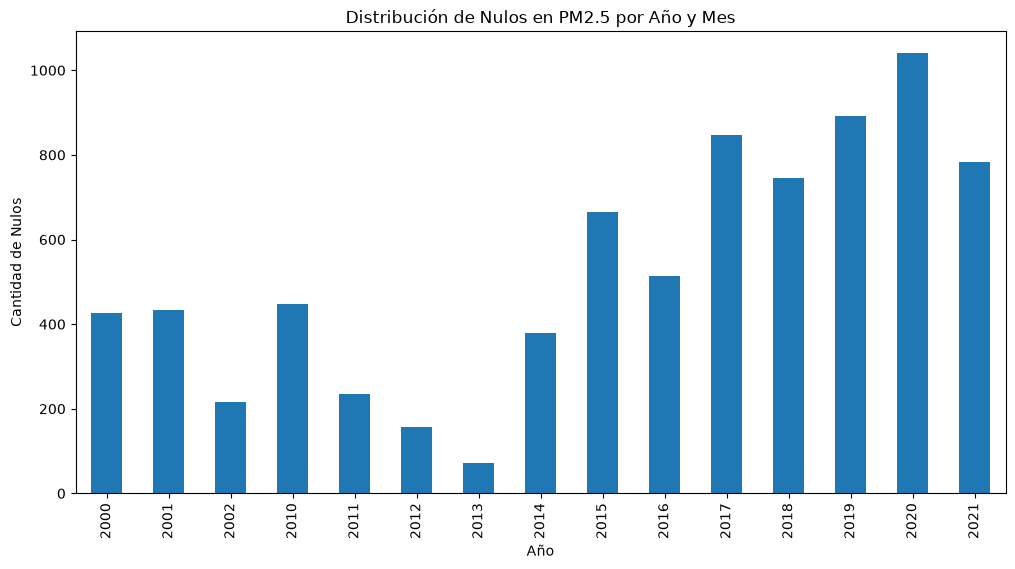

In [7]:
#revisar los nulos de la columna de PM2.5 con su año, para ver si hay algún patrón en los datos faltantes
df_nulos = df[df["PM2.5"].isnull()]
df_nulos["datetime"] = pd.to_datetime(df_nulos["datetime"], format="%Y-%m-%d")
df_nulos["year"] = df_nulos["datetime"].dt.year
#desplegar un gráfico de barras con los nulos de PM2.5 por año y mes
plt.figure(figsize=(12,6))
df_nulos.groupby("year").size().plot(kind="bar")
plt.xlabel("Año")
plt.ylabel("Cantidad de Nulos")
plt.title("Distribución de Nulos en PM2.5 por Año y Mes")
plt.show()

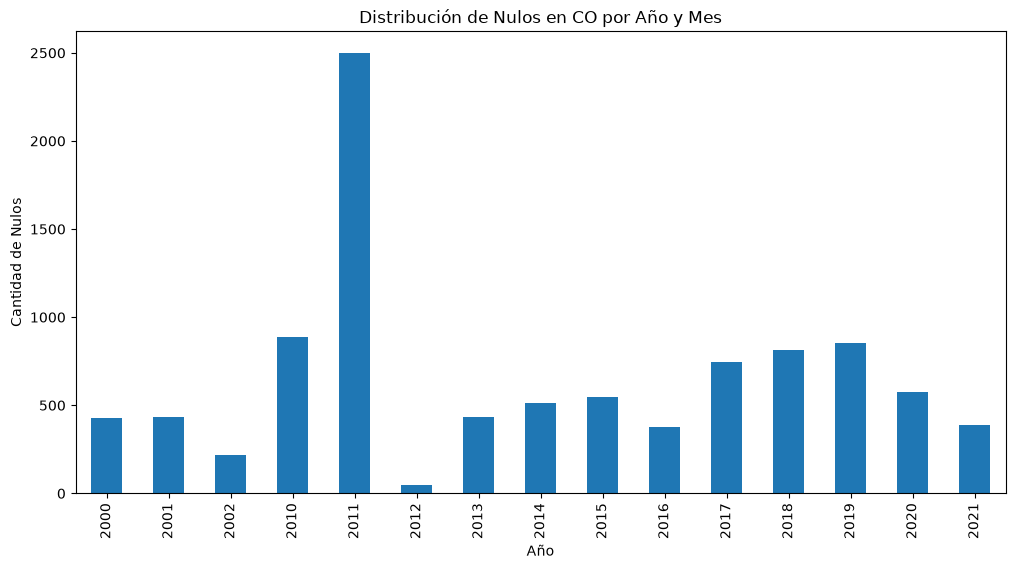

In [8]:
#revisar los nulos de la columna de CO con su año, para ver si hay algún patrón en los datos faltantes
df_nulos = df[df["CO"].isnull()]
df_nulos["datetime"] = pd.to_datetime(df_nulos["datetime"], format="%Y-%m-%d")
df_nulos["year"] = df_nulos["datetime"].dt.year
#desplegar un gráfico de barras con los nulos de CO por año y mes
plt.figure(figsize=(12,6))
df_nulos.groupby("year").size().plot(kind="bar")
plt.xlabel("Año")
plt.ylabel("Cantidad de Nulos")
plt.title("Distribución de Nulos en CO por Año y Mes")
plt.show()

---
Imputación de valores nulos
Notamos que las columnas elegidad para el modelo por su índice de correlación con '''NO2'''  contienen un gran porcentaje de nulos. Entonces, se imputaran '''O3, CO, PM2.5''' utlizando las medianas de cada estación de año para cada estación del Valle de México. 

In [9]:
def obtener_temporada(mes):
    if mes in [12, 1, 2]:
        return "Invierno"
    elif mes in [3, 4, 5]:
        return "Primavera"
    elif mes in [6, 7, 8]:
        return "Verano"
    else:
        return "Otoño"

In [10]:
variables = ["O3", "CO", "PM2.5"]

# Agregar temporada a cada conjunto
for datos in [train_df, test_df]:
    datos["temporada"] = (
        datos["datetime"].dt.month.apply(obtener_temporada)
    )

# Calcular medianas SOLO con entrenamiento
medianas = train_df.groupby(
    ["station_id", "temporada"]
)[variables].median()

# Medianas de respaldo por estación
medianas_estacion = train_df.groupby(
    "station_id"
)[variables].median()

# Medianas generales de entrenamiento
medianas_globales = train_df[variables].median()

display(medianas)

O3        CO      PM2.5
station_id temporada                               
242        Invierno   0.039944  0.600000  20.916667
           Otoño      0.031848  0.541667  15.272727
           Primavera  0.049042  0.515395  20.577381
           Verano     0.038682  0.550000  15.652174
244        Invierno   0.021396  1.010417  28.695652
           Otoño      0.020000  0.764583  21.863636
           Primavera  0.033913  0.800000  27.909091
           Verano     0.025500  0.640909  22.150000
245        Invierno   0.028417  0.714145  20.919437
           Otoño      0.026316  0.623810  14.190476
           Primavera  0.040425  0.573864  22.000000
           Verano     0.035227  0.509091  14.818182
251        Invierno   0.023792  1.033333  29.333333
           Otoño      0.022282  0.758333  20.727273
           Primavera  0.037444  0.795652  26.701993
           Verano     0.028583  0.675000  20.068182
256        Invierno   0.021361  1.200000  29.875000
           Otoño      0.020182  0.900000  21.590909
           Primavera  0.033375  0.958333  27.288538
           Verano     0.025378  0.857895  20.681159
258        Invierno   0.024085  0.950000  27.041667
           Otoño      0.023417  0.668182  15.976190
           Primavera  0.036667  0.764427  25.809524
           Verano     0.028619  0.610556  16.083333
260        Invierno   0.022381  0.958333  27.229167
           Otoño      0.021700  0.661538  18.479167
           Primavera  0.033667  0.710795  25.486842
           Verano     0.025417  0.560000  17.316667
262        Invierno   0.031375  0.600000  21.291667
           Otoño      0.023667  0.495238  15.363636
           Primavera  0.041850  0.518182  22.041667
           Verano     0.030456  0.535812  16.581169
263        Invierno   0.025458  0.870833  25.687500
           Otoño      0.024113  0.779167  18.604167
           Primavera  0.035875  0.704545  23.809524
           Verano     0.030739  0.662202  19.181818
266        Invierno   0.021250  1.000000  27.250000
           Otoño      0.020478  0.838095  21.170290
           Primavera  0.032483  0.862500  27.250000
           Verano     0.025150  0.787500  21.136364
268        Invierno   0.025417  0.910644  27.708333
           Otoño      0.023125  0.695833  21.000000
           Primavera  0.036250  0.739130  26.450000
           Verano     0.027545  0.627273  19.346591
269        Invierno   0.028583  0.826087  24.173913
           Otoño      0.024764  0.690476  15.869318
           Primavera  0.039583  0.737500  22.979167
           Verano     0.031833  0.619940  16.095238
271        Invierno   0.022604  1.252381  38.187500
           Otoño      0.022417  0.900000  22.863636
           Primavera  0.030750  0.963636  32.395833
           Verano     0.025351  0.826136  23.045455
302        Invierno   0.029408       NaN  27.458333
           Otoño      0.029765       NaN  17.568182
           Primavera  0.046864       NaN  31.613636
           Verano     0.036727       NaN  19.090909

## Tratamiento de valores faltantes

Las variables seleccionadas (`O3`, `CO` y `PM2.5`) presentan valores faltantes que debemos tratar antes del entrenamiento.

Para conservar la mayor cantidad posible de registros, utilizaremos una imputación basada en las medianas de cada estación de monitoreo y temporada del año.

Las medianas se calcularán únicamente con los datos de entrenamiento para evitar fugas de información hacia el conjunto de prueba.

In [11]:
print("Valores faltantes en entrenamiento:")
print(train_df[variables].isnull().sum())

print("\nValores faltantes en prueba:")
print(test_df[variables].isnull().sum())

print("\nMedianas generales:")
print(medianas_globales)

Valores faltantes en entrenamiento:
O3        687
CO       1959
PM2.5    3101
dtype: int64

Valores faltantes en prueba:
O3        131
CO        911
PM2.5    1862
dtype: int64

Medianas generales:
O3        0.027357
CO        0.750000
PM2.5    22.080128
dtype: float64


### Implementación del imputador estacional

Como las variables predictoras presentan valores faltantes, implementamos un transformador personalizado que utiliza medianas para completarlos.

La imputación sigue tres niveles:

1. Mediana de cada estación de monitoreo y temporada del año.
2. Mediana general de la estación, cuando no existe información suficiente para una temporada.
3. Mediana global como último recurso.

Las medianas se calculan únicamente con los datos de entrenamiento, evitando utilizar información del conjunto de prueba durante el ajuste.

In [12]:
class ImputadorEstacional(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.variables = ["O3", "CO", "PM2.5"]

        self.medianas_ = X.groupby(
            ["station_id", "temporada"]
        )[self.variables].median()

        self.medianas_estacion_ = X.groupby(
            "station_id"
        )[self.variables].median()

        self.medianas_globales_ = X[self.variables].median()

        return self

    def transform(self, X):
        X = X.copy()

        for variable in self.variables:

            # Imputar por estación y temporada
            indice = pd.MultiIndex.from_frame(
                X[["station_id", "temporada"]]
            )

            valores = pd.Series(
                self.medianas_[variable].reindex(indice).to_numpy(),
                index=X.index
            )

            # Respaldo por estación
            valores = valores.fillna(
                X["station_id"].map(
                    self.medianas_estacion_[variable]
                )
            )

            # Respaldo general
            valores = valores.fillna(
                self.medianas_globales_[variable]
            )

            # Rellenar valores faltantes
            X[variable] = X[variable].fillna(valores)

        return X[self.variables]


pipeline_preprocesamiento = Pipeline([
    ("imputacion", ImputadorEstacional())
])

In [13]:
class ImputadorEstacional(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.variables = ["O3", "CO", "PM2.5"]

        self.medianas_ = X.groupby(
            ["station_id", "temporada"]
        )[self.variables].median()

        self.medianas_estacion_ = X.groupby(
            "station_id"
        )[self.variables].median()

        self.medianas_globales_ = X[self.variables].median()

        return self

    def transform(self, X):
        X = X.copy()

        for variable in self.variables:

            # Imputar por estación y temporada
            indice = pd.MultiIndex.from_frame(
                X[["station_id", "temporada"]]
            )

            valores = pd.Series(
                self.medianas_[variable].reindex(indice).to_numpy(),
                index=X.index
            )

            # Respaldo por estación
            valores = valores.fillna(
                X["station_id"].map(
                    self.medianas_estacion_[variable]
                )
            )

            # Respaldo general
            valores = valores.fillna(
                self.medianas_globales_[variable]
            )

            # Rellenar valores faltantes
            X[variable] = X[variable].fillna(valores)

        return X[self.variables]


pipeline_preprocesamiento = Pipeline([
    ("imputacion", ImputadorEstacional())
])

## Entrenamiento y evaluación de modelos

Entrenamos tres algoritmos de regresión para estimar la concentración de NO₂ a partir de O3, CO y PM2.5:

- **Regresión Lineal Múltiple:** modelo de referencia para identificar relaciones lineales.
- **Random Forest Regressor:** combina múltiples árboles de decisión para representar relaciones no lineales.
- **Gradient Boosting Regressor:** construye árboles secuencialmente para reducir los errores de predicción.

Cada algoritmo utiliza un Pipeline que integra la imputación de datos faltantes y el entrenamiento del modelo.

Para comparar su desempeño utilizamos MAE, RMSE y R².

### Modelo 1: Regresión Lineal Múltiple

Utilizamos este algoritmo como punto de referencia (*baseline*) para comparar el desempeño de los modelos más complejos.

Su principal ventaja es que permite establecer una primera aproximación sencilla e interpretable al problema de predicción.

In [14]:

# Pipeline completo: imputación + regresión
modelo_lineal = Pipeline([
    ("imputacion", ImputadorEstacional()),
    ("modelo", LinearRegression())
])

# Entrenar únicamente con datos históricos
modelo_lineal.fit(X_train, y_train)

# Predecir NO2 en el conjunto de prueba
y_pred_lineal = modelo_lineal.predict(X_test)

# Evaluar resultados
mae = mean_absolute_error(y_test, y_pred_lineal)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lineal))
r2 = r2_score(y_test, y_pred_lineal)

print("REGRESIÓN LINEAL MÚLTIPLE")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")

NameError: name 'X_train' is not defined

### Modelo 2: Random Forest Regressor

Utilizamos Random Forest para identificar relaciones no lineales entre los contaminantes y la concentración de NO₂.

Este algoritmo combina múltiples árboles de decisión para generar predicciones más estables y reducir el riesgo de sobreajuste respecto a un árbol individual.

Su implementación nos permite evaluar si un modelo más flexible mejora los resultados obtenidos con la Regresión Lineal.

In [ ]:
# Pipeline completo
modelo_rf = Pipeline([
    ("imputacion", ImputadorEstacional()),
    ("modelo", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar
modelo_rf.fit(X_train, y_train)

# Predecir
y_pred_rf = modelo_rf.predict(X_test)

# Evaluar
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST REGRESSOR")
print(f"MAE: {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R²: {r2_rf:.4f}")

RANDOM FOREST REGRESSOR
MAE: 0.0051
RMSE: 0.0066
R²: 0.4293


### Modelo 3: Gradient Boosting Regressor

Utilizamos Gradient Boosting para mejorar las predicciones mediante la construcción secuencial de árboles de decisión.

A diferencia de Random Forest, este algoritmo entrena cada nuevo árbol buscando corregir los errores de los anteriores.

Su implementación nos permite evaluar si este aprendizaje progresivo ofrece mejores resultados que los otros dos modelos.

In [ ]:
modelo_gb = Pipeline([
    ("imputacion", ImputadorEstacional()),
    ("modelo", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [ ]:
# Entrenar el modelo Gradient Boosting
modelo_gb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
medianas_,DataFrame,...NaN 19.090909
medianas_estacion_,DataFrame,...NaN 22.825758
medianas_globales_,"Series[float64](3,)",O3 0.0...dtype: float64
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1


In [ ]:
# Predicciones de Gradient Boosting
y_pred_gb = modelo_gb.predict(X_test)

# Evaluación
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Regressor")
print(f"MAE: {mae_gb:.4f}")
print(f"RMSE: {rmse_gb:.4f}")
print(f"R²: {r2_gb:.4f}")

Gradient Boosting Regressor
MAE: 0.0051
RMSE: 0.0065
R²: 0.4504


In [ ]:
comparacion = pd.DataFrame({
    "NO2_real": y_test.to_numpy(),
    "NO2_predicho": y_pred_gb
})

comparacion["Error"] = (
    comparacion["NO2_real"] - comparacion["NO2_predicho"]
)

comparacion.head(10)

,NO2_real,NO2_predicho,Error
0,0.038652,0.040132,-0.001480
1,0.021708,0.027246,-0.005538
2,0.026750,0.033996,-0.007246
3,0.029792,0.030334,-0.000542
4,0.039875,0.035557,0.004318
5,0.031958,0.030016,0.001942
6,0.034222,0.037881,-0.003659
7,0.022455,0.028352,-0.005898
8,0.027667,0.026286,0.001381
9,0.029875,0.033363,-0.003488


## Comparación de resultados

Comparamos el desempeño de los tres modelos sobre el mismo conjunto de prueba, ordenando los resultados según el RMSE.

Gradient Boosting obtuvo el mejor desempeño, con un MAE de 0.005051, RMSE de 0.006504 y R² de 0.450361.

Posteriormente analizamos las predicciones frente a los valores reales, la distribución de los residuos y la importancia relativa de las variables.

Los resultados muestran que el modelo identifica tendencias en las concentraciones de NO₂, aunque presenta dificultades para estimar valores elevados.

In [ ]:
# Comparación de los tres modelos
resultados = pd.DataFrame({
    "Modelo": [
        "Regresión Lineal",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [mae, mae_rf, mae_gb],
    "RMSE": [rmse, rmse_rf, rmse_gb],
    "R²": [r2, r2_rf, r2_gb]
})

# Ordenar del menor al mayor RMSE
resultados = resultados.sort_values("RMSE").reset_index(drop=True)

resultados

,Modelo,MAE,RMSE,R²
0,Gradient Boosting,0.005051,0.006504,0.450361
1,Random Forest,0.005115,0.006627,0.429289
2,Regresión Lineal,0.005291,0.006760,0.406162


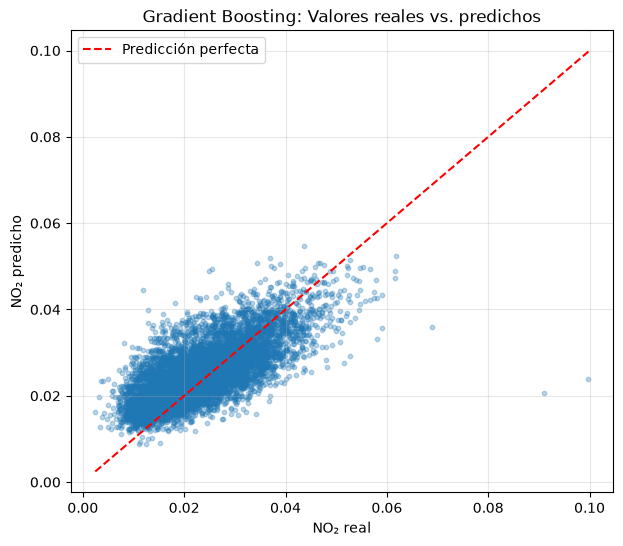

In [ ]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred_gb, alpha=0.3, s=10)

limites = [
    min(y_test.min(), y_pred_gb.min()),
    max(y_test.max(), y_pred_gb.max())
]

plt.plot(limites, limites, 'r--', label="Predicción perfecta")

plt.xlabel("NO₂ real")
plt.ylabel("NO₂ predicho")
plt.title("Gradient Boosting: Valores reales vs. predichos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

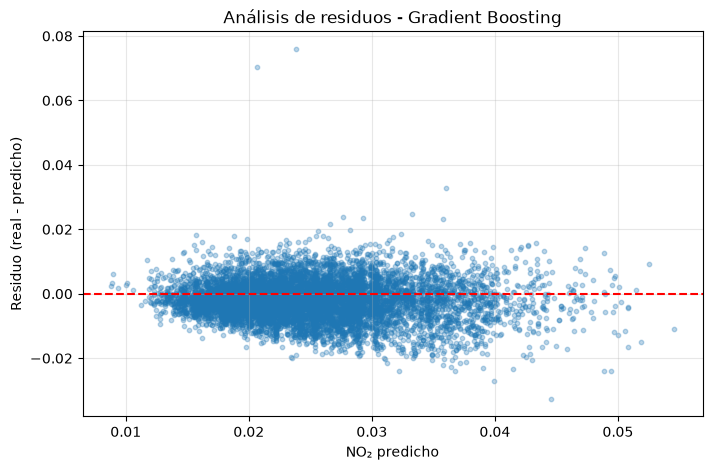

In [ ]:
# Calcular residuos
residuos_gb = y_test - y_pred_gb

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_gb, residuos_gb, alpha=0.3, s=10)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("NO₂ predicho")
plt.ylabel("Residuo (real - predicho)")
plt.title("Análisis de residuos - Gradient Boosting")

plt.grid(alpha=0.3)
plt.show()

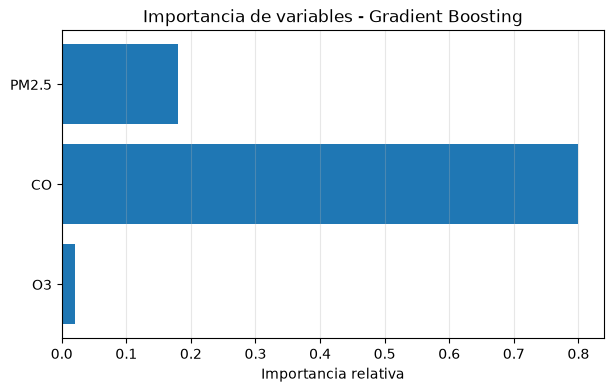

In [ ]:
# Importancia de las variables en Gradient Boosting
importancias = modelo_gb.named_steps["modelo"].feature_importances_

variables = ["O3", "CO", "PM2.5"]

plt.figure(figsize=(7, 4))
plt.barh(variables, importancias)

plt.xlabel("Importancia relativa")
plt.title("Importancia de variables - Gradient Boosting")
plt.grid(axis="x", alpha=0.3)

plt.show()

### Interpretación de los resultados de Gradient Boosting

Al comparar los valores reales contra los predichos, observamos que el modelo logra identificar una tendencia positiva entre ambas cantidades. Sin embargo, las predicciones presentan una dispersión considerable respecto a la línea ideal.

En particular, encontramos que el modelo tiende a sobreestimar las concentraciones bajas de NO₂ y subestimar las más elevadas.

El análisis de residuos confirma que existen errores importantes en determinadas observaciones, especialmente cuando las concentraciones reales son altas.

Por otro lado, el análisis de importancia de variables indica que CO es el predictor más utilizado por el modelo, seguido de PM2.5 y O3. Estas importancias reflejan su contribución predictiva dentro del algoritmo, pero no implican causalidad.

## Conclusiones del modelado

Se entrenaron y evaluaron tres algoritmos de regresión utilizando una partición temporal de los datos, con el objetivo de predecir la concentración de NO₂ en el Valle de México.

**Gradient Boosting obtuvo el mejor desempeño**, con los siguientes resultados:

| Métrica | Resultado |
|---|---:|
| MAE | 0.005051 |
| RMSE | 0.006504 |
| R² | 0.450361 |

El modelo consiguió explicar aproximadamente el 45.04 % de la variabilidad del NO₂ en el conjunto de prueba, superando a Regresión Lineal y Random Forest.

Aunque los resultados muestran que existe capacidad predictiva, también identificamos limitaciones para estimar concentraciones elevadas de contaminación. Esto representa una oportunidad de mejora mediante la incorporación de variables meteorológicas, temporales o ajustes en los hiperparámetros.

Por lo tanto, seleccionamos **Gradient Boosting como el modelo ganador de esta primera etapa**, considerando tanto sus resultados cuantitativos como las limitaciones observadas en el análisis gráfico.

## Análisis de Componentes Principales (PCA)

Aplicamos PCA para estudiar cómo se distribuye la variabilidad de las variables predictoras y determinar qué proporción puede resumirse mediante componentes principales.

Antes de aplicar PCA, utilizamos la imputación estacional y estandarizamos las variables para evitar que sus diferentes escalas influyan en el análisis.

Este procedimiento es complementario al modelado y no modifica el modelo Gradient Boosting previamente entrenado.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Recuperar la imputación entrenada
imputador = modelo_gb.named_steps["imputacion"]

# Preparar los datos de entrenamiento
X_pca = imputador.transform(X_train)

# Estandarizar las variables
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_pca)

# Aplicar PCA
pca = PCA(n_components=3)
X_componentes = pca.fit_transform(X_escalado)

# Mostrar varianza explicada
for i, varianza in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"PC{i}: {varianza * 100:.2f}%")

print(f"Varianza acumulada: {sum(pca.explained_variance_ratio_) * 100:.2f}%")

PC1: 51.14%
PC2: 37.33%
PC3: 11.53%
Varianza acumulada: 100.00%


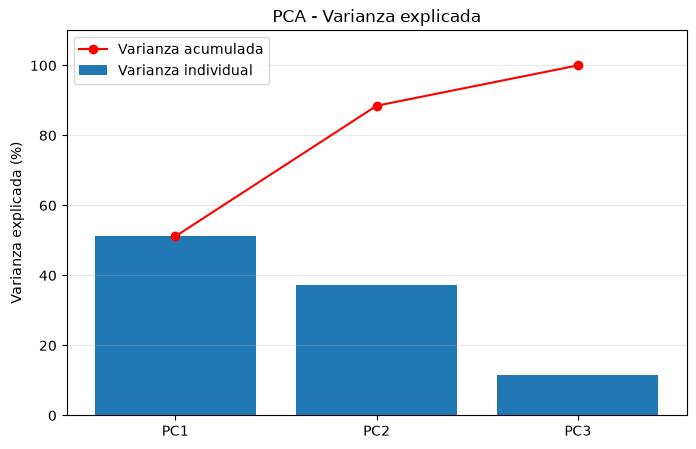

In [ ]:
varianza = pca.explained_variance_ratio_ * 100
acumulada = np.cumsum(varianza)

componentes = ["PC1", "PC2", "PC3"]

plt.figure(figsize=(8, 5))

plt.bar(componentes, varianza, label="Varianza individual")
plt.plot(componentes, acumulada, "o-",
         color="red", label="Varianza acumulada")

plt.ylabel("Varianza explicada (%)")
plt.title("PCA - Varianza explicada")
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### Interpretación del PCA

El análisis de componentes principales mostró que PC1 explica el 51.14 % de la variabilidad, PC2 el 37.33 % y PC3 el 11.53 %.

En conjunto, los primeros dos componentes representan el 88.47 % de la variabilidad total de las variables predictoras estandarizadas, lo que indica que es posible reducir la dimensionalidad conservando una proporción importante de su información.

No obstante, decidimos conservar las tres variables originales en Gradient Boosting, ya que el PCA se realizó como un análisis complementario y no se ha comprobado que la reducción dimensional mejore el desempeño predictivo.

In [ ]:
# Cargas de las variables en cada componente principal
cargas_pca = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2", "PC3"],
    index=["O3", "CO", "PM2.5"]
)

cargas_pca.round(4)

,PC1,PC2,PC3
O3,0.0448,0.9177,-0.3948
CO,0.6980,-0.3115,-0.6448
PM2.5,0.7147,0.2467,0.6545


### Interpretación de los componentes principales

El PCA permitió identificar diferentes patrones de variabilidad entre los contaminantes seleccionados.

El primer componente (PC1) está asociado principalmente con CO y PM2.5, mientras que el segundo (PC2) está dominado por O3. En conjunto, ambos explican el 88.47 % de la variabilidad de las variables estandarizadas.

Por su parte, PC3 representa principalmente un contraste entre CO y PM2.5 y explica el 11.53 % restante.

Estos resultados muestran que gran parte de la información de las tres variables puede representarse mediante dos componentes principales. Sin embargo, conservamos las variables originales en el modelo predictivo para mantener su interpretación y porque no hemos evaluado si el PCA mejora su desempeño.

In [ ]:
# 1. Métricas de los tres modelos
resultados.to_csv("metricas_modelos.csv", index=False)

# 2. Valores reales y predichos
predicciones = pd.DataFrame({
    "NO2_real": y_test.to_numpy(),
    "NO2_predicho": y_pred_gb
})

predicciones["Error"] = (
    predicciones["NO2_real"] - predicciones["NO2_predicho"]
)

predicciones.to_csv("predicciones_no2.csv", index=False)

# 3. Resultados del PCA
varianza_pca = pd.DataFrame({
    "Componente": ["PC1", "PC2", "PC3"],
    "Varianza_explicada": pca.explained_variance_ratio_ * 100,
    "Varianza_acumulada": np.cumsum(
        pca.explained_variance_ratio_
    ) * 100
})


carpeta_datasets = Path("../Datasets")
carpeta_datasets.mkdir(parents=True, exist_ok=True)

resultados.to_csv(carpeta_datasets / "metricas_modelos.csv", index=False)
predicciones.to_csv(carpeta_datasets / "predicciones_no2.csv", index=False)
varianza_pca.to_csv(carpeta_datasets / "varianza_pca.csv", index=False)

print("Los tres CSV se guardaron en Datasets.")

Los tres archivos CSV se generaron correctamente.
